In [1]:
import pandas as pd, numpy as np
d = pd.read_csv("nifty50_features.csv", parse_dates=["Date"])

d["log_ret"] = np.log(d["Close"]).diff()
d["vol_5d"]  = d["log_ret"].rolling(5).std() * np.sqrt(252) * 100
d["abs_ret"] = d["ret"].abs()
# volatility over the NEXT 5 trading days (annualised %)
d["fut_vol_5d"] = d["log_ret"].rolling(5).std().shift(-5) * np.sqrt(252) * 100

# only information known at NIFTY's close (no S&P/crude/FX moves from that night)
vfeatures = ["vol_5d", "vol_21d", "vix", "vix_chg", "abs_ret", "ret",
             "ret_lag1", "ret_lag2", "ret_lag3", "ret_lag5",
             "ma10_ratio", "ma50_ratio", "rsi14", "dow"]

dv = d.dropna(subset=vfeatures + ["fut_vol_5d"]).reset_index(drop=True)

train_v = dv[dv["Date"] < "2019-12-20"]     # small gap so target windows don't overlap validation
val_v   = dv[(dv["Date"] >= "2020-01-01") & (dv["Date"] < "2023-01-01")]
test_v  = dv[dv["Date"] >= "2023-01-01"]    # untouched until the end
print(len(train_v), len(val_v), len(test_v))

2382 746 926


In [3]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, r2_score

y = val_v["fut_vol_5d"]
rows = [
    {"model": "Baseline: current 21-day vol", "MAE": mean_absolute_error(y, val_v["vol_21d"]), "R2": r2_score(y, val_v["vol_21d"])},
    {"model": "Baseline: current India VIX",  "MAE": mean_absolute_error(y, val_v["vix"]),     "R2": r2_score(y, val_v["vix"])},
]

models = {
    "Ridge": make_pipeline(StandardScaler(), Ridge(alpha=10)),
    "Random Forest": RandomForestRegressor(n_estimators=300, max_depth=5, min_samples_leaf=30, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=200, max_depth=2, learning_rate=0.05, subsample=0.8, random_state=42),
}
for name, m in models.items():
    m.fit(train_v[vfeatures], train_v["fut_vol_5d"])
    p = m.predict(val_v[vfeatures])
    rows.append({"model": name, "MAE": mean_absolute_error(y, p), "R2": r2_score(y, p)})

print(pd.DataFrame(rows).round(3))

                          model    MAE     R2
0  Baseline: current 21-day vol  7.933  0.235
1   Baseline: current India VIX  8.506  0.423
2                         Ridge  6.376  0.518
3                 Random Forest  6.949  0.244
4             Gradient Boosting  6.852  0.318


In [5]:
rf = models["Random Forest"]
print(pd.Series(rf.feature_importances_, index=vfeatures).sort_values(ascending=False).round(3))

vix           0.548
ma50_ratio    0.220
vol_21d       0.102
rsi14         0.045
ma10_ratio    0.028
vol_5d        0.011
ret_lag1      0.010
ret           0.008
abs_ret       0.007
ret_lag2      0.007
ret_lag5      0.005
ret_lag3      0.004
vix_chg       0.004
dow           0.001
dtype: float64


In [7]:
best = models["Gradient Boosting"]       # change to whichever won on validation
trainval = dv[dv["Date"] < "2022-12-20"]
best.fit(trainval[vfeatures], trainval["fut_vol_5d"])
p = best.predict(test_v[vfeatures])
yt = test_v["fut_vol_5d"]
print("Model     MAE", round(mean_absolute_error(yt, p), 2), "| R2", round(r2_score(yt, p), 3))
print("vol_21d   MAE", round(mean_absolute_error(yt, test_v["vol_21d"]), 2), "| R2", round(r2_score(yt, test_v["vol_21d"]), 3))
print("India VIX MAE", round(mean_absolute_error(yt, test_v["vix"]), 2), "| R2", round(r2_score(yt, test_v["vix"]), 3))

Model     MAE 3.95 | R2 0.195
vol_21d   MAE 4.66 | R2 -0.233
India VIX MAE 4.84 | R2 0.086


In [9]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, r2_score

trainval = dv[dv["Date"] < "2022-12-20"]
yt = test_v["fut_vol_5d"]

ridge_final = make_pipeline(StandardScaler(), Ridge(alpha=10))
ridge_final.fit(trainval[vfeatures], trainval["fut_vol_5d"])
p_r = ridge_final.predict(test_v[vfeatures])

print("Ridge (chosen on validation)  MAE", round(mean_absolute_error(yt, p_r), 2), "| R2", round(r2_score(yt, p_r), 3))
print("Gradient Boosting             MAE 3.95 | R2 0.195")
print("vol_21d baseline              MAE", round(mean_absolute_error(yt, test_v["vol_21d"]), 2), "| R2", round(r2_score(yt, test_v["vol_21d"]), 3))
print("India VIX baseline            MAE", round(mean_absolute_error(yt, test_v["vix"]), 2), "| R2", round(r2_score(yt, test_v["vix"]), 3))

Ridge (chosen on validation)  MAE 3.72 | R2 0.251
Gradient Boosting             MAE 3.95 | R2 0.195
vol_21d baseline              MAE 4.66 | R2 -0.233
India VIX baseline            MAE 4.84 | R2 0.086


Target vol: 14.3
                             Ann. return %  Ann. volatility %  Sharpe  \
Buy & hold                            6.02              12.62    0.48   
Vol target (21d vol)                  3.09              11.68    0.26   
Vol target (Ridge forecast)           3.96              11.81    0.33   

                             Max drawdown %  Avg exposure %  
Buy & hold                           -15.77          100.00  
Vol target (21d vol)                 -18.82           95.88  
Vol target (Ridge forecast)          -17.81           97.96  


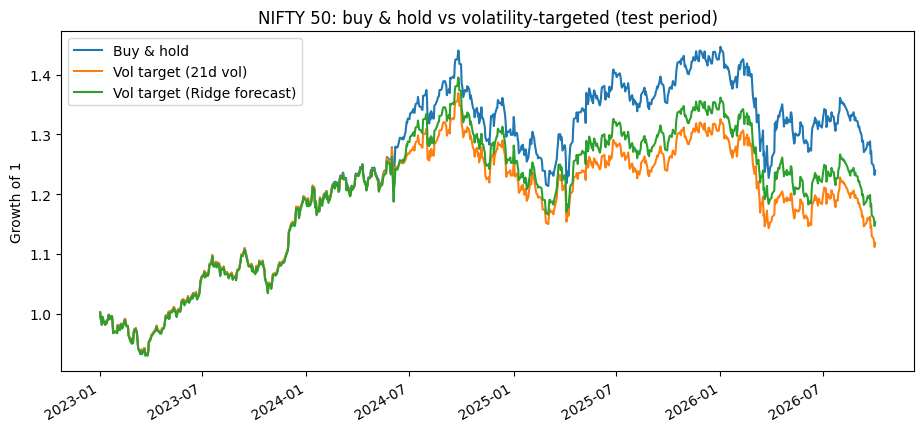

In [11]:
import numpy as np, pandas as pd

# 1) Predictions on the test period, from the model trained before 2022-12-20 (no refitting)
t = test_v.copy()
t["pred_vol"] = ridge_final.predict(t[vfeatures])

# 2) Next day's return, which is what the position held overnight earns
t["next_ret"] = t["Close"].shift(-1) / t["Close"] - 1
t = t.dropna(subset=["next_ret"]).copy()

# 3) Target volatility chosen from data BEFORE the test period (not tuned on test)
target_vol = dv.loc[dv["Date"] < "2023-01-01", "vol_21d"].median()
print("Target vol:", round(target_vol, 1))

# 4) Positions decided at the close of day t, applied to day t+1's return
t["pos_ridge"] = (target_vol / t["pred_vol"].clip(lower=5)).clip(0, 1)
t["pos_naive"] = (target_vol / t["vol_21d"].clip(lower=5)).clip(0, 1)   # simple baseline strategy
t["pos_bh"]    = 1.0                                                     # buy and hold

# 5) Returns after transaction costs (assumed 0.05% per unit of position change)
cost = 0.0005
def strat_returns(pos):
    turnover = pos.diff().abs().fillna(0)
    return pos * t["next_ret"] - turnover * cost

results = {"Buy & hold": strat_returns(t["pos_bh"]),
           "Vol target (21d vol)": strat_returns(t["pos_naive"]),
           "Vol target (Ridge forecast)": strat_returns(t["pos_ridge"])}

# 6) Metrics
def metrics(r):
    ann_ret = (1 + r).prod() ** (252 / len(r)) - 1
    ann_vol = r.std() * np.sqrt(252)
    equity = (1 + r).cumprod()
    max_dd = (equity / equity.cummax() - 1).min()
    return {"Ann. return %": ann_ret * 100, "Ann. volatility %": ann_vol * 100,
            "Sharpe": ann_ret / ann_vol, "Max drawdown %": max_dd * 100}

table = pd.DataFrame({k: metrics(v) for k, v in results.items()}).T.round(2)
table["Avg exposure %"] = [t["pos_bh"].mean() * 100, t["pos_naive"].mean() * 100, t["pos_ridge"].mean() * 100]
print(table.round(2))

# 7) Equity curves
import matplotlib.pyplot as plt
eq = pd.DataFrame({k: (1 + v).cumprod() for k, v in results.items()})
eq.index = t["Date"].values
eq.plot(figsize=(11, 5), title="NIFTY 50: buy & hold vs volatility-targeted (test period)")
plt.ylabel("Growth of 1")
plt.show()

In [13]:
eq = (1 + results["Buy & hold"]).cumprod()
eq.index = t["Date"].values
trough = (eq / eq.cummax() - 1).idxmin()
start = eq[:trough].idxmax()
print("B&H worst drawdown:", start.date(), "->", trough.date())
w = (t["Date"] >= start) & (t["Date"] <= trough)
print("Avg exposure during it (Ridge):", round(t.loc[w, "pos_ridge"].mean() * 100, 1), "%")

B&H worst drawdown: 2024-09-25 -> 2025-03-03
Avg exposure during it (Ridge): 98.0 %


In [15]:
def run_backtest(frame, model, target_vol, cost=0.0005):
    b = frame.copy()
    b["pred_vol"] = model.predict(b[vfeatures])
    b["next_ret"] = b["Close"].shift(-1) / b["Close"] - 1
    b = b.dropna(subset=["next_ret"]).copy()
    pos = {"Buy & hold": pd.Series(1.0, index=b.index),
           "Vol target (21d vol)": (target_vol / b["vol_21d"].clip(lower=5)).clip(0, 1),
           "Vol target (Ridge)": (target_vol / b["pred_vol"].clip(lower=5)).clip(0, 1)}
    out, expo = {}, {}
    for k, p in pos.items():
        r = p * b["next_ret"] - p.diff().abs().fillna(0) * cost
        out[k], expo[k] = metrics(r), p.mean() * 100
    tab = pd.DataFrame(out).T.round(2)
    tab["Avg exposure %"] = pd.Series(expo).round(1)
    return tab

tv_pre = dv.loc[dv["Date"] < "2020-01-01", "vol_21d"].median()
print("Validation 2020-2022 (target vol", round(tv_pre, 1), ")")
print(run_backtest(val_v, models["Ridge"], tv_pre))

Validation 2020-2022 (target vol 13.9 )
                      Ann. return %  Ann. volatility %  Sharpe  \
Buy & hold                    14.34              22.58    0.64   
Vol target (21d vol)          11.34              14.07    0.81   
Vol target (Ridge)            13.16              14.72    0.89   

                      Max drawdown %  Avg exposure %  
Buy & hold                    -38.44           100.0  
Vol target (21d vol)          -22.11            81.1  
Vol target (Ridge)            -20.44            87.1  


In [17]:
import joblib, json

# 1) The trained model (trained on data before 2023, the one you reported)
joblib.dump(ridge_final, "ridge_vol.joblib")

# 2) Settings the app needs
json.dump({"features": vfeatures, "target_vol": float(target_vol)}, open("app_config.json", "w"))

# 3) Data the app reads: date, close and every feature column
#    (vol_5d and abs_ret were created in this notebook, so the old features file lacks them)
d_app = d.dropna(subset=vfeatures).reset_index(drop=True)
d_app[["Date", "Close"] + vfeatures].to_csv("app_data.csv", index=False)

# 4) Equity curves from the test-period backtest
#    (rebuilt, because the drawdown check overwrote the earlier eq variable)
eq_test = pd.DataFrame({k: (1 + v).cumprod() for k, v in results.items()})
eq_test.insert(0, "Date", t["Date"].values)
eq_test.to_csv("backtest_equity_test.csv", index=False)

print(d_app.shape, d_app["Date"].max().date(), "| target vol:", round(target_vol, 1))
print(eq_test.tail(3).round(3))

(4066, 29) 2026-10-12 | target vol: 14.3
           Date  Buy & hold  Vol target (21d vol)  Vol target (Ridge forecast)
4057 2026-09-29       1.243                 1.121                        1.157
4058 2026-09-30       1.232                 1.112                        1.147
4059 2026-10-01       1.240                 1.118                        1.153
